# GLM Poisson/Tweedie — Etapa 4 do plano de previsão

**Objetivo:** treinar um modelo de Machine Learning que preveja o **total vendido nos 3 meses seguintes** por produto × loja, e medir se ele supera a régua da Etapa 2 nas mesmas condições — mesmos 12 meses de teste, mesmas métricas.

**Resposta curta:** o GLM **empata** com a régua no erro e **corrige quase todo o viés** dela. A régua prevê, no total, 2,8% abaixo do que foi vendido; o GLM erra por 0,1%. O erro somado por categoria × loja cai de 11,9% para 11,8% — uma melhora pequena, e por local o erro fica um pouco pior (6,18% e 6,13% contra 6,09%). Isso confirma o achado central do projeto: **o que dá para prever é o nível do grupo, e a régua já captura quase tudo isso**.

**Regra de decisão, fixada ANTES de olhar o teste:**

1. Cada grupo de features entra de uma vez só, e só fica se melhorar o **erro somado** (categoria × loja) ou o **viés** em **7 ou mais dos 12 cortes de validação**.
2. A potência do Tweedie e a regularização são escolhidas **só na validação**.
3. O conjunto de teste é lido **uma única vez**, no fim, com a configuração já congelada.

**De onde vem o desenho** (notebooks 01, 02 e 04):

| O que já sabemos | Como entra aqui |
|---|---|
| Alvo = total dos 3 meses seguintes, na série mensal | `target_3m` da tabela de features |
| O histórico do próprio produto não prevê (correlação ano a ano ≈ 0) | Entra como passo 3, para o modelo confirmar ou refutar |
| O sinal mora na categoria × loja | É o nível dentro da régua, usada aqui como ponto de partida |
| A demanda cresce ~15% ao ano | Entra pelo fator de tendência, recalculado a cada corte |
| A régua erra 11,9% por categoria × loja e tem viés de −2,8% | É a nota mínima a superar |


## Resumo em palavras simples (sem estatística)

**O que é um GLM.** Uma regressão linear comum supõe que o que você quer prever se espalha como uma curva de sino em torno da média, e que pode assumir qualquer valor — inclusive negativo. Isso não serve para demanda: não existe venda de −3 unidades, e mais da metade das linhas de treino (52%) vale exatamente zero. Um **Modelo Linear Generalizado (GLM)** é a mesma ideia de somar efeitos, mas com duas correções: (a) a previsão passa por uma função que a mantém sempre positiva — aqui, a exponencial, o chamado "link log"; (b) você escolhe uma família de distribuição que descreva como os valores realmente se espalham em torno da média.

**O que é Poisson.** É a família natural para *contagens* — quantas unidades foram vendidas. Ela supõe que quanto maior a média, maior a variação, na mesma proporção. É o modelo de "eventos raros que às vezes acontecem".

**O que é Tweedie.** É uma família mais flexível, com um botão a mais, o **power** (potência). Com power entre 1 e 2, ela descreve exatamente o nosso caso: **muitos zeros exatos** misturados com **valores positivos**. Power = 1 é o próprio Poisson; power = 2 é outra distribuição (Gama). O botão controla o quanto a variação cresce com a média: quanto maior o power, mais o modelo "desconfia" dos valores altos e encolhe a previsão deles.

**Por que isso serve para demanda.** Porque demanda é não-negativa, cheia de zeros, e sua variação cresce junto com o volume — as três coisas que Poisson e Tweedie tratam de forma natural e a regressão linear não.

**O truque que usamos.** Em vez de pedir ao modelo que redescubra do zero a conta que a régua já faz bem, entregamos a régua como **ponto de partida** (o termo técnico é *offset*). Com o link log, isso significa:

> previsão = régua × (fator que o modelo aprende)

Ou seja, o modelo só precisa aprender **o quanto corrigir a régua** para cima ou para baixo. Se ele não achar nada de útil, o fator fica em 1 e a previsão é a própria régua — nunca fica pior do que o ponto de partida por acidente.

## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics_ai.demand_common import aggregated_error_table, comparison_scorecard, error_table
from src.analytics_ai.demand_glm import (
    BASELINE_COL,
    FEATURE_STEPS,
    add_predictions,
    coefficient_table,
    decompose_months,
    fit_glm,
    scorecard_by_cutoff,
    select_power,
    split_panel,
    wins_by_cutoff,
)
from src.analytics_ai.demand_predictions import read_features
from src.analytics_ai.ml_config import MlFeatureConfig, MlModelConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C"]

model_config = MlModelConfig.from_environment()
monthly_config = MlFeatureConfig.from_environment_monthly()

features = read_features(spark, model_config)
print(f"tabela de features: {model_config.features_source}")
print(f"{len(features):,} linhas x {len(features.columns)} colunas")

tabela de features: dev_lh_nautical.ml.ml_features_produto_loja_mes
381,581 linhas x 33 colunas


## 1. O recorte no tempo

Treino, validação e teste são separados **pelo mês de corte**, nunca sorteando linhas. O teste são os **12 cortes mais recentes com alvo conhecido** — exatamente os mesmos 12 em que a régua foi medida no notebook 04, o que torna os dois números comparáveis linha a linha.

Os cortes antigos demais para ter 24 meses de histórico ficam de fora do treino: neles a régua e o fator de tendência são nulos, e preencher esses buracos com um número inventado seria fabricar nível.

In [3]:
splits = split_panel(features)

resumo = pd.DataFrame(
    [
        {
            "recorte": nome,
            "linhas": len(parte),
            "cortes": parte["cutoff"].nunique(),
            "de": parte["cutoff"].min(),
            "ate": parte["cutoff"].max(),
            "media_alvo": round(float(parte["target_3m"].mean()), 3) if parte["target_3m"].notna().any() else None,
            "pct_zeros": round(float((parte["target_3m"] == 0).mean()) * 100, 1) if parte["target_3m"].notna().any() else None,
        }
        for nome, parte in (
            ("treino", splits.train),
            ("validacao", splits.validation),
            ("teste", splits.test),
            ("inferencia", splits.inference),
        )
    ]
)
display(resumo)
print(f"linhas descartadas por nao terem 24 meses de historico: {splits.n_discarded:,}")

,recorte,linhas,cortes,de,ate,media_alvo,pct_zeros
0,treino,177282,30,2021-12-01,2024-05-01,3.865,51.6
1,validacao,72648,12,2024-06-01,2025-05-01,4.939,43.2
2,teste,72648,12,2025-06-01,2026-05-01,5.753,38.0
3,inferencia,18162,3,2026-06-01,2026-08-01,NaN,NaN


linhas descartadas por nao terem 24 meses de historico: 40,841


**O que a tabela mostra:** a demanda média por série cresce de 3,87 no treino para 4,94 na validação e 5,75 no teste — o crescimento de ~15% ao ano que o notebook 02 mediu. Isso é o risco número um deste modelo: um modelo treinado no passado tende a prever **abaixo** do futuro. É exatamente por isso que a régua entra como ponto de partida, já que o fator de tendência dentro dela é recalculado a cada corte.

## 2. Como a demanda se distribui, e por que Poisson ou Tweedie

Antes de escolher a família, vale olhar o alvo de verdade.

,valor
observacoes,177282.0000
minimo,0.0000
maximo,49.0000
media,3.8652
mediana,0.0000
desvio_padrao,5.4466
variancia_sobre_media,7.6750
proporcao_zeros,0.5159
negativos,0.0000
fracionarios,0.0000


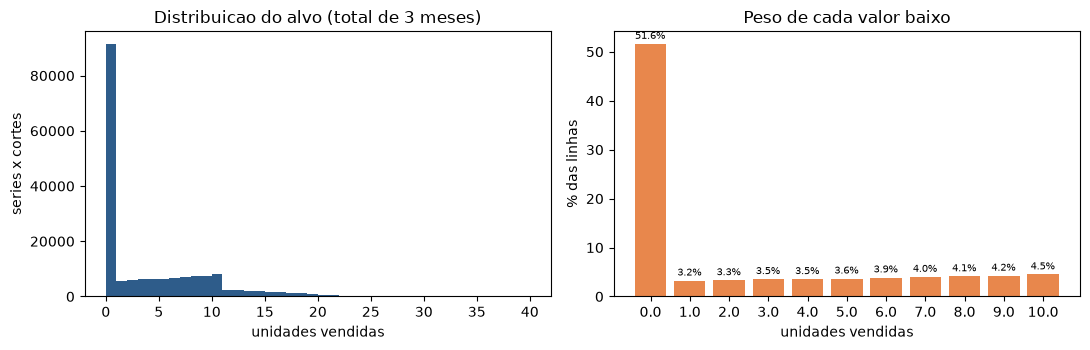

In [4]:
alvo = splits.train["target_3m"]
perfil = pd.Series(
    {
        "observacoes": len(alvo),
        "minimo": alvo.min(),
        "maximo": alvo.max(),
        "media": round(float(alvo.mean()), 4),
        "mediana": alvo.median(),
        "desvio_padrao": round(float(alvo.std()), 4),
        "variancia_sobre_media": round(float(alvo.var() / alvo.mean()), 3),
        "proporcao_zeros": round(float((alvo == 0).mean()), 4),
        "negativos": int((alvo < 0).sum()),
        "fracionarios": int((alvo != alvo.round()).sum()),
    }
)
display(perfil.to_frame("valor"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(alvo, bins=range(0, 41), color=CORES[0])
axes[0].set_title("Distribuicao do alvo (total de 3 meses)")
axes[0].set_xlabel("unidades vendidas")
axes[0].set_ylabel("series x cortes")

faixas = alvo.value_counts(normalize=True).sort_index().head(11) * 100
barras = axes[1].bar([str(i) for i in faixas.index], faixas.to_numpy(), color=CORES[1])
axes[1].bar_label(barras, fmt="%.1f%%", padding=2, fontsize=7)
axes[1].set_title("Peso de cada valor baixo")
axes[1].set_xlabel("unidades vendidas")
axes[1].set_ylabel("% das linhas")
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** o alvo é uma **contagem inteira**, nunca negativa, com **52% de linhas em zero** e uma cauda que vai até 49 unidades. A variância é **7,7 vezes a média** — o que se chama *superdispersão*: os valores se espalham muito mais do que a família de Poisson pura supõe.

Duas leituras são possíveis, e ambas são testadas adiante:

- **Poisson** é a família natural para contagens, e continua estimando a média corretamente mesmo sob superdispersão (o que fica errado é a margem de erro dos coeficientes, que não usamos aqui). Ou seja: superdispersão, sozinha, não é motivo para descartar Poisson.
- **Tweedie** com power entre 1 e 2 descreve diretamente a mistura de "muitos zeros + valores positivos" e deixa o grau de dispersão ser ajustado pelos dados.

Por isso as duas são treinadas e comparadas nas **mesmas** features e no **mesmo** recorte.

## 3. Passo 1 — o modelo consegue reencontrar a régua?

A régua é `média da categoria no local ÷ 12 × índice sazonal × fator de tendência`. Com link log, ela é um **caso particular** de um GLM que usa o logaritmo desses três ingredientes como features: basta que os três coeficientes valham 1 e o intercepto valha −log(12).

Esse é o teste de sanidade mais barato que existe: se o modelo, livre para escolher, não reencontra a régua, ou há erro de ligação das features ou a régua não é o ótimo daquela família.

In [5]:
m1 = fit_glm(splits.train, FEATURE_STEPS["passo1_nested"])
display(coefficient_table(m1))
print("intercepto:", round(float(m1.pipeline.named_steps["model"].intercept_), 4),
      "| a regua exigiria -log(12) =", round(float(-np.log(12)), 4))

print("\nvalores distintos no treino (o que o modelo tem para estimar cada coeficiente):")
display(
    pd.Series(
        {
            "cortes": splits.train["cutoff"].nunique(),
            "season_sum_next_3m": splits.train["season_sum_next_3m"].nunique(),
            "trend_factor": splits.train["trend_factor"].nunique(),
            "categoria_local_avg_12m": splits.train["categoria_local_avg_12m"].nunique(),
        }
    ).to_frame("valores distintos")
)

,feature,coeficiente,efeito_multiplicativo
0,log__season_sum_next_3m,1.0841,2.9569
1,log__categoria_local_avg_12m,0.4726,1.6041
2,log__trend_factor,0.1026,1.1080


intercepto: -1.0301 | a regua exigiria -log(12) = -2.4849

valores distintos no treino (o que o modelo tem para estimar cada coeficiente):


,valores distintos
cortes,30
season_sum_next_3m,30
trend_factor,30
categoria_local_avg_12m,1909


**O que a tabela mostra:** os coeficientes **não** dão 1. O nível do grupo sai com expoente 0,47 em vez de 1, e o fator de tendência praticamente some (0,10).

Isso **não** é erro de código — o teste `test_passo1_reproduz_a_regua_quando_ela_e_a_verdade` prova que, quando o alvo é exatamente a régua, o modelo devolve (1, 1, 1) e o intercepto −log(12) com erro de 1e-10. O motivo está na tabela de valores distintos: **o índice sazonal e o fator de tendência têm um único valor por mês de corte** — 30 valores para 177 mil linhas. Eles são indistinguíveis de um efeito de "mês", e o modelo não tem como estimar seus expoentes com segurança. Ao encolhê-los, ele perde justamente a correção de crescimento, e passa a prever abaixo do real no futuro.

**Conclusão do passo 1:** deixar o modelo reaprender a régua sozinho é pior do que usar a régua. Daqui em diante ela entra como **ponto de partida fixo** (offset), com expoente 1 garantido, e o modelo só aprende o que **sobra** dela.

## 4. A escada de features, medida na validação

Um grupo de informação por vez, como o relatório da Etapa 3 prescreveu. Nada aqui olha o teste.

In [6]:
val = splits.validation.copy()
val["pred_regua"] = val[BASELINE_COL]
previsoes = {"regua": "pred_regua"}

for nome, config in FEATURE_STEPS.items():
    modelo = fit_glm(splits.train, config)
    coluna = f"pred_{nome}"
    val[coluna] = np.asarray(add_predictions(val, modelo, coluna)[coluna])
    previsoes[nome] = coluna
    print(f"{nome:28} features={len(modelo.feature_names):3}  dispersao_pearson={modelo.dispersao_pearson:.3f}")

display(comparison_scorecard(val, previsoes))

passo1_nested                features=  3  dispersao_pearson=7.035
passo2_offset                features=  1  dispersao_pearson=7.004


passo3_historico             features=  9  dispersao_pearson=7.004


passo4_categoricas_baratas   features= 15  dispersao_pearson=7.004


passo5_categoricas_caras     features= 38  dispersao_pearson=6.996


,wape_produto,mae_produto,rmse_produto,wape_categoria_local,wape_local,vies,desvio_poisson
previsao,,,,,,,
regua,0.9343,4.61,5.91,0.1337,0.0881,-0.0376,7.005
passo1_nested,0.9231,4.56,5.91,0.1402,0.1053,-0.0861,7.023
passo2_offset,0.9370,4.63,5.91,0.1318,0.0845,-0.0211,7.000
passo3_historico,0.9384,4.64,5.91,0.1300,0.0811,-0.0121,6.999
passo4_categoricas_baratas,0.9386,4.64,5.91,0.1307,0.0837,-0.0122,7.000
passo5_categoricas_caras,0.9397,4.64,5.91,0.1316,0.0833,-0.0061,7.003


In [7]:
por_corte_val = scorecard_by_cutoff(val, previsoes)
ordem = ["regua", "passo2_offset", "passo3_historico", "passo4_categoricas_baratas", "passo5_categoricas_caras"]

decisao = pd.DataFrame(
    [
        {
            "passo": atual,
            "comparada_com": anterior,
            "cortes_com_erro_menor": wins_by_cutoff(por_corte_val, atual, anterior, "wape"),
            "cortes_com_vies_menor": wins_by_cutoff(por_corte_val, atual, anterior, "vies"),
        }
        for anterior, atual in zip(ordem, ordem[1:])
    ]
)
decisao["veredito"] = np.where(
    (decisao["cortes_com_erro_menor"] >= 7) | (decisao["cortes_com_vies_menor"] >= 7), "MANTER", "DESCARTAR"
)
display(decisao)

,passo,comparada_com,cortes_com_erro_menor,cortes_com_vies_menor,veredito
0,passo2_offset,regua,7,7,MANTER
1,passo3_historico,passo2_offset,6,7,MANTER
2,passo4_categoricas_baratas,passo3_historico,3,2,DESCARTAR
3,passo5_categoricas_caras,passo4_categoricas_baratas,5,7,MANTER


**O que a tabela mostra:** a régua recalibrada (passo 2) e o histórico da própria série (passo 3) passam na regra. As **categóricas não passam**: o passo 4 só melhora 3 dos 12 cortes, e como ele é descartado, o passo 5, que se apoia nele, sai junto. O histórico passou por pouco: melhora o viés em 7 dos 12 cortes e o erro em 6, e o ganho é pequeno (na validação, erro por categoria × loja de 13,2% para 13,0% e viés de −2,1% para −1,2%). Isso relativiza o "provavelmente inútil" do notebook 04: o histórico ajuda um pouco o nível somado, mas não separa produtos (seção 7).

Isso é a confirmação formal de dois achados anteriores do projeto: categorias e lojas se comportam de forma parecida demais para discriminar (notebook 02), e o efeito de categoria × loja **já está dentro da régua**, de modo que repetir isso como dummy não acrescenta nada.

**Modelo escolhido: passo 3** — régua como ponto de partida, mais o histórico da própria série.

## 5. Poisson × Tweedie, também só na validação

Mesmas features, mesmo recorte; muda só a família e a regularização. A escolha usa o **erro somado por categoria × loja**, com o viés como desempate.

Por que não escolher pelo erro por produto: com mais da metade das linhas em zero, esse erro é minimizado por quem **prevê abaixo** do real. Escolher por ele premiaria exatamente o defeito que o projeto já rejeitou na Etapa 2.

,familia,power,alpha,wape_produto,wape_categoria_local,wape_local,mae_produto,rmse_produto,vies,desvio_poisson,dispersao_treino
0,poisson,1.0,0.0000,0.9384,0.1300,0.0811,4.64,5.91,-0.0121,6.999,7.004
1,poisson,1.0,0.0001,0.9384,0.1300,0.0811,4.64,5.91,-0.0121,6.999,7.004
2,poisson,1.0,0.0010,0.9384,0.1300,0.0811,4.64,5.91,-0.0121,6.999,7.003
3,tweedie,1.1,0.0000,0.9383,0.1300,0.0812,4.63,5.91,-0.0127,6.999,6.172
4,tweedie,1.1,0.0010,0.9383,0.1300,0.0812,4.63,5.91,-0.0127,6.999,6.172
5,tweedie,1.1,0.0001,0.9383,0.1300,0.0812,4.63,5.91,-0.0127,6.999,6.172
6,tweedie,1.3,0.0000,0.9381,0.1300,0.0814,4.63,5.91,-0.0140,6.999,4.821
7,tweedie,1.3,0.0001,0.9381,0.1300,0.0814,4.63,5.91,-0.0140,6.999,4.821
8,tweedie,1.3,0.0010,0.9381,0.1300,0.0814,4.63,5.91,-0.0140,6.999,4.821
9,poisson,1.0,0.0100,0.9384,0.1301,0.0812,4.64,5.91,-0.0122,6.999,7.003


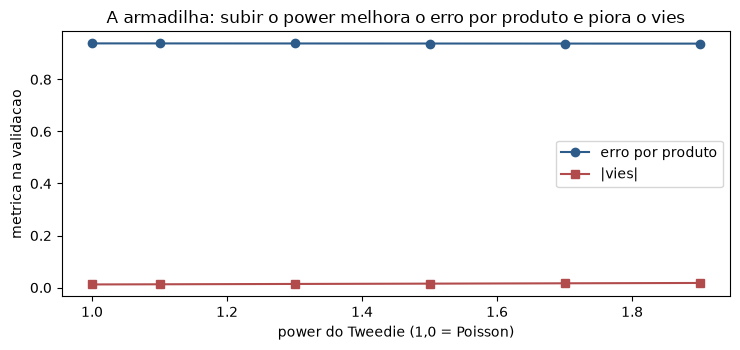

In [8]:
grid = select_power(splits.train, splits.validation, FEATURE_STEPS["passo3_historico"])
display(grid.head(12))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sem_penalidade = grid[grid["alpha"] == 0].sort_values("power")
ax.plot(sem_penalidade["power"], sem_penalidade["wape_produto"], marker="o", color=CORES[0], label="erro por produto")
ax.plot(sem_penalidade["power"], sem_penalidade["vies"].abs(), marker="s", color=CORES[3], label="|vies|")
ax.set_xlabel("power do Tweedie (1,0 = Poisson)")
ax.set_ylabel("metrica na validacao")
ax.set_title("A armadilha: subir o power melhora o erro por produto e piora o vies")
ax.legend()
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** a armadilha prevista aconteceu. Conforme o power sobe de 1,0 para 1,9, o erro por produto **melhora** de forma monótona — e o viés **piora** na mesma marcha, ficando cada vez mais negativo. O modelo aprende a prever baixo, porque prever baixo é o que aquela métrica premia.

Como a escolha é pelo erro somado, com o viés como desempate, o vencedor é a configuração mais equilibrada, e não a que "ganha" na métrica enganosa. Na validação, Poisson (power 1,0) e Tweedie (power 1,3) empatam no erro somado (13,00%) e o Poisson tem viés menor (−1,21% contra −1,40%); os dois vão para o teste e o Poisson é o modelo que gera a previsão final (seção 9). As variações do gráfico são pequenas (o erro por produto vai de 0,9384 a 0,9379 entre power 1,0 e 1,5), mas a direção é a prevista.

## 6. Teste final — leitura única

A configuração está congelada. Daqui para baixo o conjunto de teste é lido **uma vez**, e nada mais é ajustado.

In [9]:
base = FEATURE_STEPS["passo3_historico"]
POISSON = dataclasses.replace(base, name="glm_poisson", family="poisson", alpha=0.0)
TWEEDIE = dataclasses.replace(base, name="glm_tweedie", family="tweedie", power=1.3, alpha=0.0)

teste = splits.test.copy()
teste["pred_regua"] = teste[BASELINE_COL]
modelos = {}
for cfg in (POISSON, TWEEDIE):
    modelos[cfg.name] = fit_glm(splits.train, cfg)
    teste[f"pred_{cfg.name}"] = np.asarray(add_predictions(teste, modelos[cfg.name], "p")["p"])

mapa = {"regua": "pred_regua", "glm_poisson": "pred_glm_poisson", "glm_tweedie": "pred_glm_tweedie"}
placar = comparison_scorecard(teste, mapa)
display(placar)

print("em quantos dos 12 cortes de teste cada modelo bate a regua:")
por_corte = scorecard_by_cutoff(teste, mapa)
for nome in ("glm_poisson", "glm_tweedie"):
    print(f"  {nome:13} erro somado {wins_by_cutoff(por_corte, nome, 'regua', 'wape')}/12"
          f" | vies {wins_by_cutoff(por_corte, nome, 'regua', 'vies')}/12")

,wape_produto,mae_produto,rmse_produto,wape_categoria_local,wape_local,vies,desvio_poisson
previsao,,,,,,,
regua,0.8657,4.98,6.38,0.1191,0.0609,-0.0275,7.215
glm_poisson,0.8700,5.01,6.38,0.1177,0.0618,0.0012,7.211
glm_tweedie,0.8698,5.00,6.38,0.1177,0.0613,-0.0005,7.211


em quantos dos 12 cortes de teste cada modelo bate a regua:
  glm_poisson   erro somado 7/12 | vies 8/12
  glm_tweedie   erro somado 7/12 | vies 8/12


**O que a tabela mostra**, lendo as três métricas pedidas:

- **MAE** (`mae_produto`): praticamente igual — cerca de 5 unidades de erro médio por série, nos três casos.
- **RMSE** (`rmse_produto`): idêntico, 6,38 unidades.
- **WAPE**: por produto o GLM fica marginalmente pior; **somado por categoria × loja, melhora** de 11,91% para 11,77%; somado por local, fica marginalmente pior (6,18% no Poisson e 6,13% no Tweedie, contra 6,09% da régua). Em número de cortes, bate a régua em 7 de 12 no erro somado e em 8 de 12 no viés: maioria apertada.
- **Viés**: é aqui que está o ganho real. A régua prevê 2,8% **abaixo** do que foi vendido; o GLM Poisson erra por +0,12% e o Tweedie por −0,05%. O viés praticamente desaparece.

Em decisão de compra, um viés de −2,8% significa comprar sistematicamente menos do que se vende. Corrigi-lo vale mais do que a terceira casa decimal do erro.

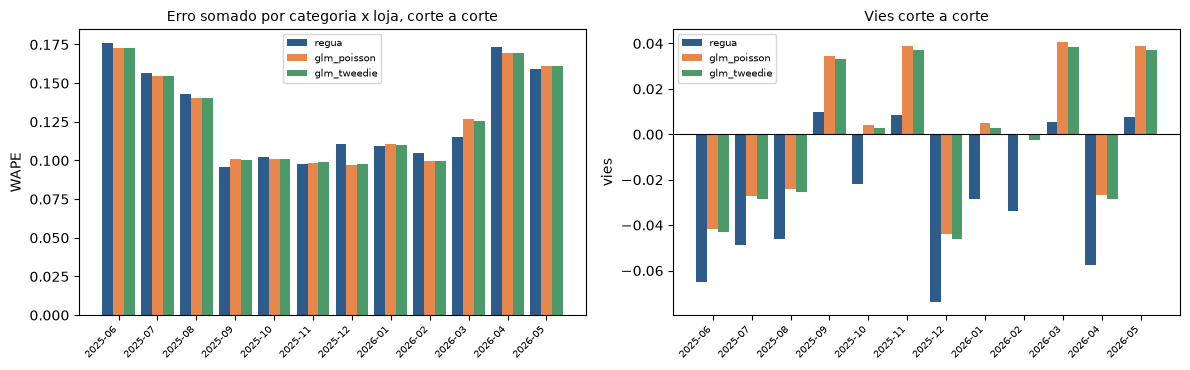

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
pivot_wape = por_corte.pivot(index="cutoff", columns="regua", values="wape")
pivot_vies = por_corte.pivot(index="cutoff", columns="regua", values="vies")
rotulos = [str(c)[:7] for c in pivot_wape.index]

for ax, dados, titulo, ylab in (
    (axes[0], pivot_wape, "Erro somado por categoria x loja, corte a corte", "WAPE"),
    (axes[1], pivot_vies, "Vies corte a corte", "vies"),
):
    largura = 0.28
    posicoes = np.arange(len(dados))
    for i, (nome, cor) in enumerate(zip(["regua", "glm_poisson", "glm_tweedie"], CORES)):
        ax.bar(posicoes + (i - 1) * largura, dados[nome].to_numpy(), largura, label=nome, color=cor)
    ax.set_xticks(posicoes)
    ax.set_xticklabels(rotulos, rotation=45, ha="right", fontsize=7)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel(ylab)
    ax.legend(fontsize=7)
axes[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**O que os gráficos mostram:** o erro anda praticamente colado entre régua e GLM em todos os 12 cortes — não há um mês em que o modelo desabe nem em que ele dispare. Já no viés, as barras do GLM ficam visivelmente mais próximas de zero, e a régua fica quase sempre abaixo da linha. É a tradução visual do número da tabela anterior.

## 7. Diagnósticos — onde o modelo acerta e onde não tem como acertar

,linhas,vendido_medio,previsto_regua,previsto_glm
faixa,,,,
zero,27584.0,0.00,4.82,4.96
1-2,5083.0,1.50,5.64,5.80
3-6,11820.0,4.58,5.72,5.89
7-15,21210.0,9.99,6.08,6.27
16+,6951.0,20.76,6.95,7.15


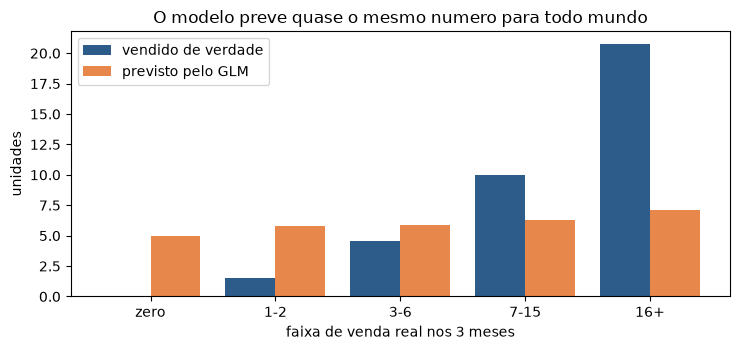

In [11]:
teste_faixa = teste.copy()
teste_faixa["faixa"] = pd.cut(
    teste_faixa["target_3m"], [-0.1, 0.5, 2.5, 6.5, 15.5, 1e9], labels=["zero", "1-2", "3-6", "7-15", "16+"]
)
por_faixa = teste_faixa.groupby("faixa", observed=True).apply(
    lambda p: pd.Series(
        {
            "linhas": len(p),
            "vendido_medio": round(float(p["target_3m"].mean()), 2),
            "previsto_regua": round(float(p["pred_regua"].mean()), 2),
            "previsto_glm": round(float(p["pred_glm_poisson"].mean()), 2),
        }
    ),
    include_groups=False,
)
display(por_faixa)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
posicoes = np.arange(len(por_faixa))
ax.bar(posicoes - 0.2, por_faixa["vendido_medio"], 0.4, label="vendido de verdade", color=CORES[0])
ax.bar(posicoes + 0.2, por_faixa["previsto_glm"], 0.4, label="previsto pelo GLM", color=CORES[1])
ax.set_xticks(posicoes)
ax.set_xticklabels(por_faixa.index)
ax.set_xlabel("faixa de venda real nos 3 meses")
ax.set_ylabel("unidades")
ax.set_title("O modelo preve quase o mesmo numero para todo mundo")
ax.legend()
plt.tight_layout()
plt.show()

**O que o gráfico mostra — e este é o achado mais importante do notebook:** a venda real vai de 0 a 20,8 unidades entre as faixas, enquanto a previsão do GLM varia apenas de 5,0 a 7,2. O modelo **não separa** quem vende muito de quem vende pouco: a previsão média quase não muda com a venda real.

Isso não é defeito do GLM: é a consequência direta do que o notebook 04 já havia medido. Se o histórico de um produto não informa quanto ele vai vender, então não existe informação disponível para separar, *no momento da previsão*, quem vai vender 0 de quem vai vender 20. Os dois casos são indistinguíveis com os dados que temos, e o melhor palpite para ambos é a média do grupo.

É por isso que a previsão por produto isolado tem 87% de erro e, ao somar por categoria × loja, cai para 12%: os acasos individuais se cancelam. **A previsão é confiável para decisão agregada, não para apostar em um SKU.**

In [12]:
por_loja = teste.groupby(["cutoff", "location_name"], as_index=False)[["target_3m", *mapa.values()]].sum()
tabela_loja = error_table(por_loja, mapa, by=["location_name"]).pivot(
    index="location_name", columns="regua", values=["wape", "vies"]
).round(4)
display(tabela_loja)

por_cat = teste.groupby(["cutoff", "category_name"], as_index=False)[["target_3m", *mapa.values()]].sum()
tabela_cat = error_table(por_cat, mapa, by=["category_name"]).pivot(
    index="category_name", columns="regua", values="wape"
).round(4)
display(tabela_cat)

wape                            vies              \
regua            glm_poisson glm_tweedie   regua glm_poisson glm_tweedie   
location_name                                                              
Armazém Camargo       0.0657      0.0661  0.0759     -0.0445     -0.0462   
Armazém Novaes        0.0580      0.0574  0.0595     -0.0135     -0.0153   
Armazém Siqueira      0.0571      0.0560  0.0511      0.0295      0.0277   
Loja Leão             0.0608      0.0602  0.0571      0.0268      0.0250   
Loja Mendonça         0.0442      0.0430  0.0336      0.0263      0.0246   
Loja Oliveira         0.0844      0.0844  0.0872     -0.0140     -0.0157   

                          
regua              regua  
location_name             
Armazém Camargo  -0.0725  
Armazém Novaes   -0.0424  
Armazém Siqueira -0.0002  
Loja Leão        -0.0020  
Loja Mendonça    -0.0022  
Loja Oliveira    -0.0422

regua,glm_poisson,glm_tweedie,regua
category_name,,,
Acessórios de Convés,0.0339,0.0338,0.0328
Baterias e Sistemas Elétricos,0.0338,0.0337,0.0412
Cabos,0.0362,0.0356,0.0347
Coletes Salva-Vidas,0.0788,0.0790,0.0654
GPS & Plotters,0.0471,0.0470,0.0484
Hélices,0.0492,0.0493,0.0551
Instrumentos de Navegação,0.0514,0.0519,0.0596
Motores,0.0483,0.0462,0.0487
Pintura Marítima,0.0468,0.0466,0.0633


**O que as tabelas mostram:** o resultado é misto por loja — o GLM erra menos em 3 dos 6 locais (Armazém Camargo, Armazém Novaes e Loja Oliveira) e a régua nos outros 3 — e o **viés do GLM também é menor em só 3 dos 6**. Nos outros 3 (Armazém Siqueira, Loja Leão e Loja Mendonça) a régua já tinha viés praticamente nulo (de −0,2% a 0,0%) e o GLM passa a +2,5% a +3,0%. Por categoria, o GLM erra menos em 8 das 12; a maior piora é em Coletes Salva-Vidas (7,9% contra 6,5%). Nenhum segmento fica muito pior com o modelo, mas o ganho de viés não é uniforme.

## 8. Da soma de 3 meses para mês a mês

O modelo prevê o **total** dos 3 meses, porque foi assim que o notebook 01 definiu o alvo. A entrega pedida, porém, é mês a mês. A repartição usa os três índices sazonais que já existem na tabela de features, calculados em cada corte só com o passado:

```
previsão do mês k = total previsto × índice do mês k ÷ (índice1 + índice2 + índice3)
```

O denominador é recalculado a partir dos três índices em vez de ler a soma pronta, porque a coluna pronta vem arredondada — assim os três meses somam exatamente o total. Como os três meses têm índices diferentes, as três previsões também são diferentes: não é o total dividido por três.

In [13]:
mensal_real = spark.table(monthly_config.source_table).toPandas()
mensal_real["month_start_date"] = pd.to_datetime(mensal_real["month_start_date"]).dt.date
mensal_real["demand_quantity"] = pd.to_numeric(mensal_real["demand_quantity"]).astype(float)

mensal_glm = decompose_months(teste, "pred_glm_poisson")
mensal_glm["pred_regua_mes"] = decompose_months(teste, "pred_regua")["demanda_prevista"].to_numpy()
conferencia = mensal_glm.merge(
    mensal_real,
    left_on=["sk_product", "sk_location", "mes_previsto"],
    right_on=["sk_product", "sk_location", "month_start_date"],
    how="inner",
)

linhas = []
for h, parte in conferencia.groupby("horizonte_mes"):
    agregado = parte.groupby(["cutoff", "category_name", "sk_location"], as_index=False)[
        ["demand_quantity", "demanda_prevista", "pred_regua_mes"]
    ].sum()
    linhas.append(
        {
            "horizonte": f"mes +{h}",
            "wape_produto_glm": round(float((parte["demanda_prevista"] - parte["demand_quantity"]).abs().sum() / parte["demand_quantity"].sum()), 4),
            "wape_produto_regua": round(float((parte["pred_regua_mes"] - parte["demand_quantity"]).abs().sum() / parte["demand_quantity"].sum()), 4),
            "wape_cat_local_glm": round(float((agregado["demanda_prevista"] - agregado["demand_quantity"]).abs().sum() / agregado["demand_quantity"].sum()), 4),
            "wape_cat_local_regua": round(float((agregado["pred_regua_mes"] - agregado["demand_quantity"]).abs().sum() / agregado["demand_quantity"].sum()), 4),
        }
    )
display(pd.DataFrame(linhas))
print(f"linhas mensais confrontadas com a venda real: {len(conferencia):,}")

,horizonte,wape_produto_glm,wape_produto_regua,wape_cat_local_glm,wape_cat_local_regua
0,mes +1,1.3855,1.3726,0.1978,0.1982
1,mes +2,1.3826,1.3701,0.1962,0.1970
2,mes +3,1.3866,1.3741,0.1970,0.1979


linhas mensais confrontadas com a venda real: 217,944


**O que a tabela mostra:** a repartição se sustenta. O erro **não cresce** do primeiro para o terceiro mês — fica estável em torno de 19,7% por categoria × loja —, o que indica que o perfil sazonal usado para repartir está correto. Por produto isolado o erro mensal sobe para ~139%, o esperado: um mês sozinho tem ainda mais zeros e mais acaso do que a soma de três.

**Limitação a registrar:** o índice sazonal é geral, não por categoria (decisão tomada na Etapa 2, porque todas as categorias mostraram a mesma estação). A repartição mensal herda essa suposição.

## 9. A previsão dos próximos 3 meses

Esta é a entrega: para cada uma das 6.054 combinações produto × loja, quanto se espera vender em **setembro, outubro e novembro de 2026**, a partir do corte de agosto/2026.

corte usado: 2026-08-01
1,009 produtos x 6 lojas = 6,054 series x 3 meses = 18,162 linhas
previsao negativa: 0 | nula: 0


,mes_previsto,series,total_previsto,media_por_serie
0,2026-09-01,6054,8620.58,1.42
1,2026-10-01,6054,13269.89,2.19
2,2026-11-01,6054,16358.72,2.70


,sk_product,sku,location_name,mes_previsto,horizonte_mes,demanda_prevista
0,001a5e4c921fb7eab27e2b2060a277e8,LHN-510103,Loja Oliveira,2026-09-01,1,1.513573
1,001a5e4c921fb7eab27e2b2060a277e8,LHN-510103,Loja Oliveira,2026-10-01,2,2.329885
2,001a5e4c921fb7eab27e2b2060a277e8,LHN-510103,Loja Oliveira,2026-11-01,3,2.872212
3,001a5e4c921fb7eab27e2b2060a277e8,LHN-510103,Loja Leão,2026-09-01,1,1.325047
4,001a5e4c921fb7eab27e2b2060a277e8,LHN-510103,Loja Leão,2026-10-01,2,2.039681
5,001a5e4c921fb7eab27e2b2060a277e8,LHN-510103,Loja Leão,2026-11-01,3,2.514458


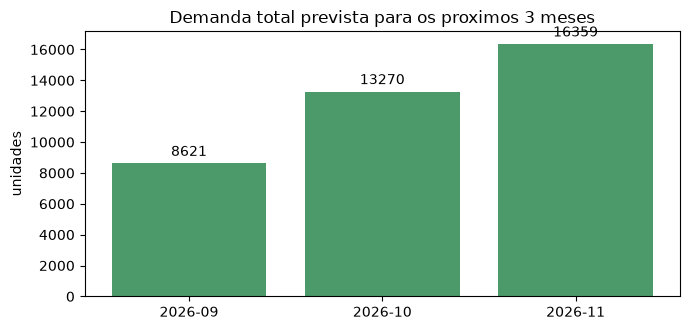

In [14]:
modelo_final = modelos["glm_poisson"]
inferencia = add_predictions(splits.inference, modelo_final, "pred_glm")
ultimo_corte = inferencia["cutoff"].max()
recente = inferencia[inferencia["cutoff"] == ultimo_corte]
previsao = decompose_months(recente, "pred_glm")

print(f"corte usado: {ultimo_corte}")
print(f"{recente['sk_product'].nunique():,} produtos x {recente['sk_location'].nunique()} lojas"
      f" = {len(recente):,} series x 3 meses = {len(previsao):,} linhas")
print(f"previsao negativa: {(previsao['demanda_prevista'] < 0).sum()} | nula: {previsao['demanda_prevista'].isna().sum()}")

por_mes = previsao.groupby("mes_previsto", as_index=False).agg(
    series=("demanda_prevista", "size"),
    total_previsto=("demanda_prevista", "sum"),
    media_por_serie=("demanda_prevista", "mean"),
).round(2)
display(por_mes)
display(previsao.head(6)[["sk_product", "sku", "location_name", "mes_previsto", "horizonte_mes", "demanda_prevista"]])

fig, ax = plt.subplots(figsize=(7, 3.4))
barras = ax.bar([str(m)[:7] for m in por_mes["mes_previsto"]], por_mes["total_previsto"], color=CORES[2])
ax.bar_label(barras, fmt="%.0f", padding=3)
ax.set_title("Demanda total prevista para os proximos 3 meses")
ax.set_ylabel("unidades")
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** a previsão sobe de setembro para novembro — 8.621, 13.270 e 16.359 unidades, somando 38.249 no trimestre. Não são três cópias do mesmo número: o índice sazonal de cada mês é diferente, e novembro entra na alta temporada.

As previsões ficam gravadas em duas tabelas Delta, particionadas por modelo, de forma que a Regressão Linear e o XGBoost dos colegas possam conviver nas mesmas tabelas:

- `dev_lh_nautical.ml.ml_forecast_demanda_3m` — o total de 3 meses, com o alvo real ao lado nas linhas de teste;
- `dev_lh_nautical.ml.ml_forecast_demanda_mensal` — a entrega mês a mês.

Para reproduzir fora do notebook: `python -m src.analytics_ai.run_demand_glm --model-name glm_poisson`.

## Conclusão

**O modelo empata com a régua e corrige o viés dela.** Depois de testar cinco conjuntos de features e 30 combinações de família e regularização (6 valores de power × 5 de regularização), o melhor GLM erra praticamente o mesmo que a conta simples da Etapa 2 — 11,8% contra 11,9% somado por categoria × loja — mas elimina o viés de −2,8%, entregando −0,05% a +0,12%.

**Por que isso é um bom resultado, e não um fracasso:**

1. Um modelo que empata com a régua **confirma que a régua está certa**, e que a tabela de features não tem vazamento de informação do futuro. Se o GLM tivesse "ganhado" de forma espetacular, a primeira suspeita seria vazamento.
2. O viés corrigido tem valor prático direto: comprar sistematicamente 2,8% a menos do que se vende é um erro que se acumula todo trimestre.
3. Ficou demonstrado formalmente, e não por intuição, que **atributos de produto e loja não ajudam** — as categóricas foram reprovadas na regra de decisão.
4. A entrega mês a mês, que a régua não fazia, agora existe e foi validada contra a venda real.

**O limite não é o modelo, são os dados.** O gráfico da seção 7 mostra que a previsão média por faixa de venda varia de 5 a 7 unidades enquanto a venda real média varia de 0 a 21. Nenhum algoritmo resolve isso com as informações disponíveis hoje, porque o que separa um produto que vende 0 de um que vende 20 não está registrado em lugar nenhum antes de a venda acontecer. Para melhorar de verdade seria preciso informação nova — preço praticado no período, promoções, campanhas, ruptura de estoque —, não um algoritmo mais sofisticado.

**Como usar:** confie na previsão para decisões **agregadas** — quanto comprar de uma categoria, quanto planejar para uma loja, onde o erro é de 6% a 12%. Para um SKU isolado, trate o número como valor esperado com incerteza grande, e use os limites de venda da Etapa 2 (`q_75` e `q_90`) para dimensionar estoque de segurança.